# TP2 — Modèles génératifs avec PyTorch : MNIST

**Première partie : classifieur, autoencodeur simple et autoencodeur variationnel.**

Ce travail suit les supports « Modèles génératifs avec PyTorch » de **Pr. Mohamed YOUSSFI,
ENSET, Université Hassan II de Casablanca**, fournis avec l'énoncé.
Le notebook reprend leurs architectures pédagogiques et complète l'évaluation,
la reproductibilité et l'exploration. Toutes les cellules de code sont autonomes dans ce carnet.

## Objectifs

1. Configurer un projet Python avec UV et charger MNIST.
2. Créer, entraîner et tester un modèle discriminatif qui prédit le chiffre.
3. Créer, entraîner, évaluer et explorer un autoencodeur qui reconstruit son entrée.
4. Créer, entraîner, évaluer et explorer un VAE qui permet aussi de générer des images.

## Résultats de l'exécution de référence

Exécution complète sur **55,000 images d'entraînement**, **5,000 de validation** et **10,000 de test**, avec une graine fixée à 42 et un espace latent de dimension 2.

- **Classifieur : 96.15% de précision**, F1 macro = 0.9610.
- **Autoencodeur : MSE de test = 0.04126 par pixel** ; référence image moyenne = 0.06747.
- **VAE : MSE de test = 0.03945 par pixel** pour le décodage de la moyenne latente ; objectif BCE + KL estimé par 5 tirages = 147.34 par image.

Les tableaux et figures ci-dessous détaillent ces mesures. La MSE des deux autoencodeurs est comparable ; la perte de classification, la MSE et l'objectif du VAE ont des définitions différentes. Ces valeurs décrivent l'exécution enregistrée ; une nouvelle exécution recalcule les résultats dans les cellules et fichiers de sortie.

## 0. Environnement Python avec UV dans VS Code

Pour créer un projet équivalent depuis un dossier vide :

```powershell
uv init --python 3.11
uv python pin 3.11
uv venv --python 3.11
.\.venv\Scripts\Activate.ps1
uv add torch==2.10.0 torchvision==0.25.0 torcheval==0.0.7 matplotlib numpy ipykernel nbformat nbclient nbconvert
```

Sous Linux/macOS, l'activation est `source .venv/bin/activate`.
Dans le projet livré, les fichiers de configuration existent : **`uv sync --locked` suffit**.
Ouvrir ce notebook dans VS Code et choisir le noyau `.venv` (Python 3.11).
La commande de l'énoncé `.venv/Script/Activate` devient bien `.venv\Scripts\Activate.ps1` sous PowerShell.

**Protocole fixé avant les tests :** graine 42 ; 55 000 images d'apprentissage et
5 000 de validation issues du lot officiel d'entraînement ; les 10 000 images officielles
de test sont réservées à l'évaluation finale. Aucun hyperparamètre n'est choisi sur le test.
Les labels servent à entraîner le classifieur ; ils ne servent pas à entraîner l'AE ou le VAE.
La dimension latente est **2**, pour permettre une visualisation directe, au prix d'une forte compression.

In [1]:
import copy
import csv
import importlib.metadata
import json
import os
from pathlib import Path
import platform
import random
import time

import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision import datasets, transforms
from torcheval.metrics.functional import multiclass_accuracy
from IPython.display import Markdown, display

SEED = 42
BATCH_SIZE = 256
LATENT_DIM = 2
EPOCHS_CLASSIFIER, EPOCHS_AE, EPOCHS_VAE = 5, 15, 20
LEARNING_RATE = 1e-3
BETA = 1.0
MC_TEST = 5
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "resultats"
FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "modeles"
for directory in (OUTPUT_DIR, FIGURE_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True)
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
versions = {package: importlib.metadata.version(package)
            for package in ("torch", "torchvision", "torcheval", "numpy", "matplotlib")}
print("Python :", platform.python_version())
print("Versions :", versions)
print("Périphérique :", device)
print("Graine :", SEED)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 140, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "figure.facecolor": "white"})

def save_figure(name):
    plt.savefig(FIGURE_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()

Matplotlib is building the font cache; this may take a moment.


Python : 3.11.18
Versions : {'torch': '2.10.0', 'torchvision': '0.25.0', 'torcheval': '0.0.7', 'numpy': '2.4.6', 'matplotlib': '3.11.2'}
Périphérique : cpu
Graine : 42


## 1. Charger et examiner MNIST

MNIST contient des images en niveaux de gris de **28 × 28 pixels** et dix classes (0 à 9).
`ToTensor()` transforme les pixels entiers de 0 à 255 en nombres flottants dans `[0, 1]`.
Cette plage correspond à la sortie sigmoïde des décodeurs. Aucune normalisation centrée
n'est appliquée, car elle serait incompatible avec la cible de reconstruction du VAE.

Le téléchargement utilise `torchvision.datasets.MNIST`. Pour accélérer les nombreuses
époques sur CPU, les mêmes images sont ensuite converties une seule fois en tenseurs.
La séparation est reproductible et les indices d'apprentissage/validation sont disjoints.

In [2]:
mnist_train = datasets.MNIST(DATA_DIR, train=True, download=True, transform=transforms.ToTensor())
mnist_test = datasets.MNIST(DATA_DIR, train=False, download=True, transform=transforms.ToTensor())
full_train = TensorDataset(mnist_train.data.unsqueeze(1).float().div_(255), mnist_train.targets)
test_dataset = TensorDataset(mnist_test.data.unsqueeze(1).float().div_(255), mnist_test.targets)
split_indices = torch.randperm(len(full_train), generator=torch.Generator().manual_seed(SEED))
train_indices, validation_indices = split_indices[:55000], split_indices[55000:]
train_dataset = Subset(full_train, train_indices.tolist())
validation_dataset = Subset(full_train, validation_indices.tolist())
assert len(set(train_dataset.indices) & set(validation_dataset.indices)) == 0
assert len(train_dataset) + len(validation_dataset) == 60000
assert len(test_dataset) == 10000
assert torch.equal(full_train[0][0], mnist_train[0][0])

def make_train_loader():
    # Une nouvelle graine de mélange identique pour chaque expérience.
    return DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                      generator=torch.Generator().manual_seed(SEED))

train_loader = make_train_loader()
train_eval_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Apprentissage : {len(train_dataset):,} | Validation : {len(validation_dataset):,} | Test : {len(test_dataset):,}")
images, labels = next(iter(train_eval_loader))
assert images.shape[1:] == (1, 28, 28) and 0 <= images.min() <= images.max() <= 1
print("Forme d'un lot :", tuple(images.shape), "| Type :", images.dtype)
print("Effectifs par chiffre — apprentissage / validation / test")
for digit in range(10):
    counts = [int((targets == digit).sum()) for targets in
              (mnist_train.targets[train_indices], mnist_train.targets[validation_indices], mnist_test.targets)]
    print(f"{digit} : {counts[0]:5d} / {counts[1]:4d} / {counts[2]:4d}")

Apprentissage : 55,000 | Validation : 5,000 | Test : 10,000
Forme d'un lot : (256, 1, 28, 28) | Type : torch.float32
Effectifs par chiffre — apprentissage / validation / test
0 :  5441 /  482 /  980
1 :  6190 /  552 / 1135
2 :  5477 /  481 / 1032
3 :  5600 /  531 / 1010
4 :  5346 /  496 /  982
5 :  5000 /  421 /  892
6 :  5422 /  496 /  958
7 :  5710 /  555 / 1028
8 :  5347 /  504 /  974
9 :  5467 /  482 / 1009


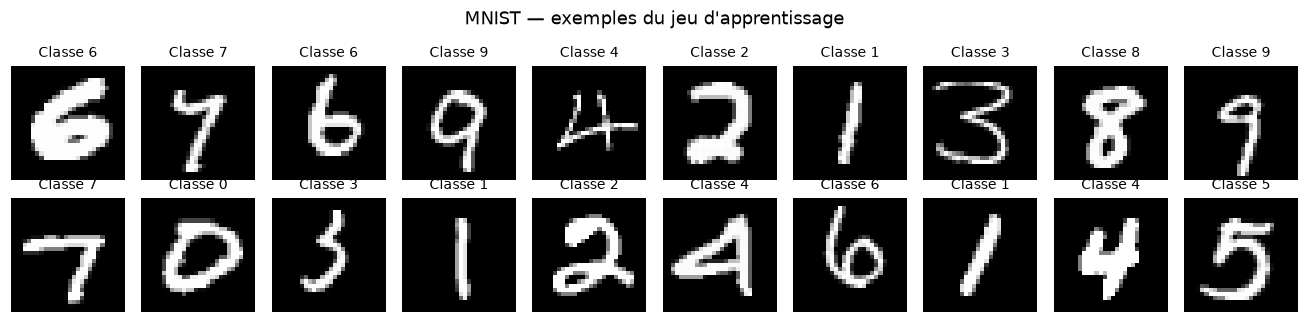

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for index, ax in enumerate(axes.flat):
    ax.imshow(images[index, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe {labels[index].item()}", fontsize=9)
    ax.axis("off")
fig.suptitle("MNIST — exemples du jeu d'apprentissage")
fig.tight_layout()
save_figure("01_exemples_mnist")

## 2. Créer, entraîner et évaluer le modèle discriminatif

Le classifieur apprend une approximation de **P(y | x)**. Il transforme une image en dix
scores appelés *logits* : `784 → 128 (ReLU) → 10`.
`Flatten` transforme `[B, 1, 28, 28]` en `[B, 784]`.
`CrossEntropyLoss` combine le log-softmax et la log-vraisemblance négative : il ne faut
pas placer de softmax dans la dernière couche pendant l'entraînement.
Adam met à jour les paramètres après `zero_grad`, `backward` et `step`.

L'accuracy est le nombre de prédictions correctes divisé par le nombre d'images.
La validation sert à retenir la meilleure époque ; le test est évalué après ce choix.

In [4]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))

    def forward(self, x):
        return self.net(x)

def classifier_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = F.cross_entropy(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * len(x)
            correct += (logits.argmax(1) == y).sum().item()
            count += len(x)
    return {"loss": loss_sum / count, "accuracy": correct / count}

def fit(model, epoch_function, epochs, name, selection_metric="loss"):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loader = make_train_loader()
    history, best_score, best_epoch, best_state = [], float("inf"), 0, None
    started = time.perf_counter()
    for epoch in range(1, epochs + 1):
        train_metrics = epoch_function(model, loader, optimizer)
        validation_metrics = epoch_function(model, validation_loader)
        row = {"epoch": epoch, **{f"train_{key}": value for key, value in train_metrics.items()},
               **{f"val_{key}": value for key, value in validation_metrics.items()}}
        history.append(row)
        if validation_metrics[selection_metric] < best_score:
            best_score, best_epoch = validation_metrics[selection_metric], epoch
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        print(f"{name} {epoch:02d}/{epochs} | apprentissage={train_metrics[selection_metric]:.5f} "
              f"| validation={validation_metrics[selection_metric]:.5f}", flush=True)
    model.load_state_dict(best_state)
    model.eval()
    torch.save({"state_dict": best_state, "best_epoch": best_epoch, "seed": SEED,
                "latent_dim": LATENT_DIM, "name": name}, MODEL_DIR / f"{name}.pt")
    with (OUTPUT_DIR / f"historique_{name}.csv").open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    duration = time.perf_counter() - started
    print(f"Meilleure époque retenue : {best_epoch} | durée : {duration:.1f} s")
    return history, best_epoch, duration

seed_everything()
classifier = Classifier().to(device)
print(classifier)
history_classifier, best_classifier, time_classifier = fit(classifier, classifier_epoch, EPOCHS_CLASSIFIER, "classifieur")

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


classifieur 01/5 | apprentissage=0.53324 | validation=0.30225


classifieur 02/5 | apprentissage=0.25001 | validation=0.23502


classifieur 03/5 | apprentissage=0.19258 | validation=0.19161


classifieur 04/5 | apprentissage=0.15470 | validation=0.17184


classifieur 05/5 | apprentissage=0.12939 | validation=0.14964


Meilleure époque retenue : 5 | durée : 11.8 s


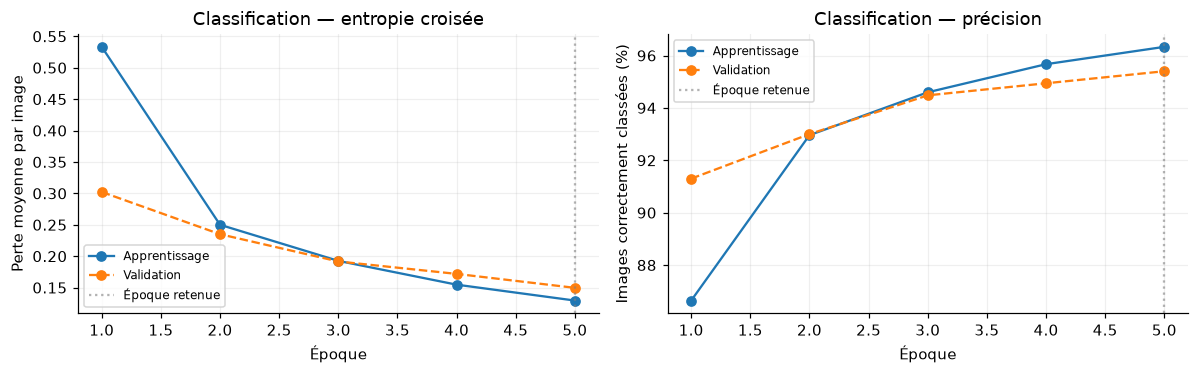

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, key, title, ylabel, scale in (
    (axes[0], "loss", "Classification — entropie croisée", "Perte moyenne par image", 1),
    (axes[1], "accuracy", "Classification — précision", "Images correctement classées (%)", 100),
):
    for prefix, label, style in (("train", "Apprentissage", "-"), ("val", "Validation", "--")):
        ax.plot([row["epoch"] for row in history_classifier],
                [scale * row[f"{prefix}_{key}"] for row in history_classifier], style, marker="o", label=label)
    ax.axvline(best_classifier, color="gray", alpha=.6, linestyle=":", label="Époque retenue")
    ax.set(title=title, xlabel="Époque", ylabel=ylabel)
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.tight_layout()
save_figure("02_courbes_classifieur")

### 2.1 Test final, F1 macro et matrice de confusion

`eval()` configure les couches pour l'inférence ; `no_grad()` désactive le calcul des gradients.
Ces deux opérations ont des rôles différents. On vérifie l'accuracy calculée manuellement
avec la fonction de **Torcheval** demandée dans l'énoncé.
La matrice de confusion a les vraies classes en lignes et les classes prédites en colonnes.
Le F1 macro accorde le même poids aux dix classes.

In [6]:
@torch.no_grad()
def predict_classifier(model, loader):
    model.eval()
    true_labels, predicted_labels = [], []
    for x, y in loader:
        true_labels.append(y)
        predicted_labels.append(model(x.to(device)).argmax(1).cpu())
    return torch.cat(true_labels), torch.cat(predicted_labels)

y_true, y_pred = predict_classifier(classifier, test_loader)
accuracy = (y_true == y_pred).float().mean().item()
accuracy_torcheval = multiclass_accuracy(y_pred, y_true, num_classes=10, average="micro").item()
assert abs(accuracy - accuracy_torcheval) < 1e-6
confusion = torch.bincount(10 * y_true + y_pred, minlength=100).reshape(10, 10)
assert confusion.sum().item() == len(test_dataset)
true_positive = confusion.diag().float()
precision = true_positive / confusion.sum(0).clamp_min(1)
recall = true_positive / confusion.sum(1).clamp_min(1)
f1 = 2 * precision * recall / (precision + recall).clamp_min(1e-12)
test_classifier = classifier_epoch(classifier, test_loader)
test_classifier.update({"accuracy": accuracy, "f1_macro": f1.mean().item(), "best_epoch": best_classifier})
display(Markdown(f"**Précision de test : {accuracy:.2%}** ; F1 macro : **{f1.mean().item():.4f}** ; "
                 f"erreurs : **{int((y_true != y_pred).sum())} / {len(test_dataset)}**."))
print("Classe | Précision | Rappel | F1 | Effectif")
for digit in range(10):
    print(f"{digit:6d} | {precision[digit]:9.3f} | {recall[digit]:6.3f} | {f1[digit]:.3f} | {confusion[digit].sum():8d}")

**Précision de test : 96.15%** ; F1 macro : **0.9610** ; erreurs : **385 / 10000**.

Classe | Précision | Rappel | F1 | Effectif
     0 |     0.974 |  0.984 | 0.979 |      980
     1 |     0.980 |  0.990 | 0.985 |     1135
     2 |     0.966 |  0.960 | 0.963 |     1032
     3 |     0.935 |  0.968 | 0.951 |     1010
     4 |     0.960 |  0.963 | 0.962 |      982
     5 |     0.960 |  0.945 | 0.953 |      892
     6 |     0.956 |  0.963 | 0.960 |      958
     7 |     0.954 |  0.968 | 0.961 |     1028
     8 |     0.958 |  0.929 | 0.943 |      974
     9 |     0.970 |  0.938 | 0.954 |     1009


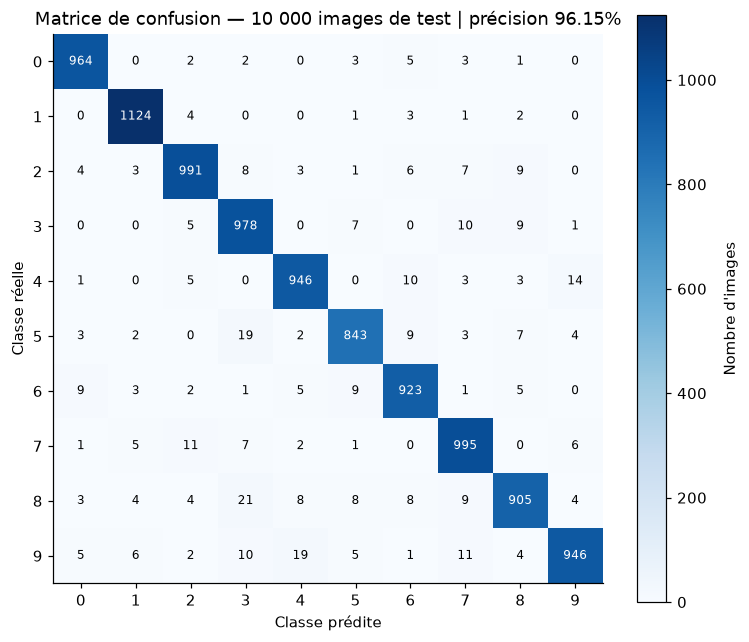

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(confusion.numpy(), cmap="Blues", vmin=0)
threshold = confusion.max().item() / 2
for row in range(10):
    for column in range(10):
        value = confusion[row, column].item()
        ax.text(column, row, str(value), ha="center", va="center", fontsize=8,
                color="white" if value > threshold else "black")
ax.set(xticks=range(10), yticks=range(10), xlabel="Classe prédite", ylabel="Classe réelle",
       title=f"Matrice de confusion — 10 000 images de test | précision {accuracy:.2%}")
fig.colorbar(im, ax=ax, label="Nombre d'images")
fig.tight_layout()
save_figure("03_matrice_confusion")

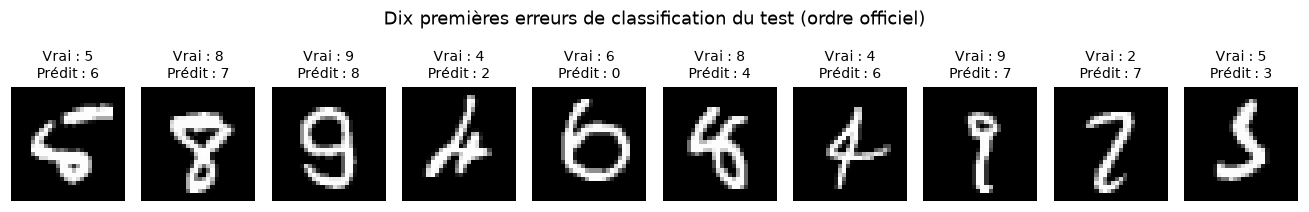

**Interprétation.** Le classifieur apprend à reconnaître les classes à partir d'exemples étiquetés. Les cases hors diagonale identifient ses confusions. Il ne possède pas de décodeur et ne génère pas d'images.

In [8]:
error_indices = torch.where(y_true != y_pred)[0][:10]
if len(error_indices):
    fig, axes = plt.subplots(1, len(error_indices), figsize=(12, 2.2), squeeze=False)
    for ax, index in zip(axes.flat, error_indices.tolist()):
        ax.imshow(test_dataset[index][0][0], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"Vrai : {y_true[index]}\nPrédit : {y_pred[index]}", fontsize=9)
        ax.axis("off")
    fig.suptitle("Dix premières erreurs de classification du test (ordre officiel)")
    fig.tight_layout()
    save_figure("04_erreurs_classifieur")
else:
    print("Aucune erreur sur le test.")
display(Markdown("**Interprétation.** Le classifieur apprend à reconnaître les classes à partir d'exemples étiquetés. "
                 "Les cases hors diagonale identifient ses confusions. Il ne possède pas de décodeur et ne génère pas d'images."))

## 3. Créer, entraîner, évaluer et explorer un autoencodeur simple

L'autoencodeur réalise `image → encodeur → z → décodeur → image reconstruite`.
L'architecture reprend le support : encodeur `784 → 128 → 32 → 2`, décodeur `2 → 32 → 128 → 784`.
Les couches cachées utilisent ReLU ; la dernière couche utilise Sigmoid pour produire des pixels dans `[0, 1]`.

On minimise la **MSE moyenne par pixel** :

$$\mathcal L_{AE}=\frac{1}{B\,784}\sum_{i=1}^{B}\sum_{p=1}^{784}(x_{ip}-\hat x_{ip})^2.$$

Les étiquettes sont ignorées pendant l'apprentissage : la cible est l'image d'entrée elle-même.
Une dimension latente de 2 compresse 784 valeurs en deux coordonnées ; certaines informations sont perdues.

In [9]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
                                     nn.Linear(128, 32), nn.ReLU(), nn.Linear(32, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 32), nn.ReLU(), nn.Linear(32, 128),
                                     nn.ReLU(), nn.Linear(128, 784), nn.Sigmoid())

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).reshape(-1, 1, 28, 28)

    def forward(self, x):
        return self.decode(self.encode(x))

def autoencoder_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    squared_error, pixels = 0.0, 0
    with torch.set_grad_enabled(training):
        for x, _ in loader:
            x = x.to(device)
            reconstruction = model(x)
            loss = F.mse_loss(reconstruction, x)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            squared_error += F.mse_loss(reconstruction.detach(), x, reduction="sum").item()
            pixels += x.numel()
    return {"mse": squared_error / pixels}

seed_everything()
ae = Autoencoder().to(device)
history_ae, best_ae, time_ae = fit(ae, autoencoder_epoch, EPOCHS_AE, "autoencodeur", "mse")
test_ae = autoencoder_epoch(ae, test_loader)

autoencodeur 01/15 | apprentissage=0.07637 | validation=0.05720


autoencodeur 02/15 | apprentissage=0.05520 | validation=0.05353


autoencodeur 03/15 | apprentissage=0.05255 | validation=0.05124


autoencodeur 04/15 | apprentissage=0.05018 | validation=0.04898


autoencodeur 05/15 | apprentissage=0.04793 | validation=0.04696


autoencodeur 06/15 | apprentissage=0.04629 | validation=0.04570


... (6 outputs left out)

autoencodeur 13/15 | apprentissage=0.04176 | validation=0.04183


autoencodeur 14/15 | apprentissage=0.04143 | validation=0.04157


autoencodeur 15/15 | apprentissage=0.04123 | validation=0.04133


Meilleure époque retenue : 15 | durée : 79.8 s


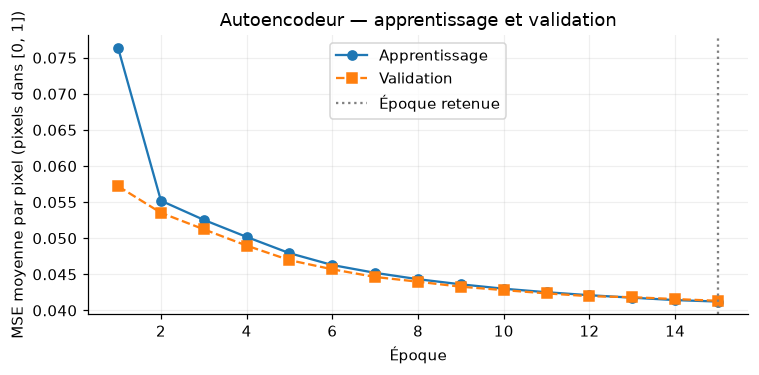

In [10]:
def plot_reconstruction_history(history, best_epoch, title, name):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot([row["epoch"] for row in history], [row["train_mse"] for row in history], "-o", label="Apprentissage")
    ax.plot([row["epoch"] for row in history], [row["val_mse"] for row in history], "--s", label="Validation")
    ax.axvline(best_epoch, linestyle=":", color="gray", label="Époque retenue")
    ax.set(title=title, xlabel="Époque", ylabel="MSE moyenne par pixel (pixels dans [0, 1])")
    ax.grid(alpha=.2)
    ax.legend()
    fig.tight_layout()
    save_figure(name)

plot_reconstruction_history(history_ae, best_ae, "Autoencodeur — apprentissage et validation", "05_courbes_ae")

### 3.1 Comparer à une référence sans apprentissage de représentation

Prédire toujours l'image moyenne d'apprentissage donne une référence simple. Elle est
calculée exclusivement sur l'apprentissage, puis évaluée sur le même test que les modèles.
Cela évite de considérer une faible erreur comme satisfaisante sans point de comparaison.

In [11]:
mean_image = torch.zeros(1, 1, 28, 28)
for x, _ in train_eval_loader:
    mean_image += x.sum(0, keepdim=True)
mean_image /= len(train_dataset)
baseline_error, baseline_pixels = 0.0, 0
for x, _ in test_loader:
    baseline_error += F.mse_loss(mean_image.expand_as(x), x, reduction="sum").item()
    baseline_pixels += x.numel()
baseline_mse = baseline_error / baseline_pixels
test_ae.update({"baseline_mse": baseline_mse, "best_epoch": best_ae})
display(Markdown(f"**MSE de l'AE : {test_ae['mse']:.5f} par pixel** ; référence image moyenne : "
                 f"**{baseline_mse:.5f}**. Réduction relative de MSE : **{1 - test_ae['mse'] / baseline_mse:.1%}**."))

**MSE de l'AE : 0.04126 par pixel** ; référence image moyenne : **0.06747**. Réduction relative de MSE : **38.8%**.

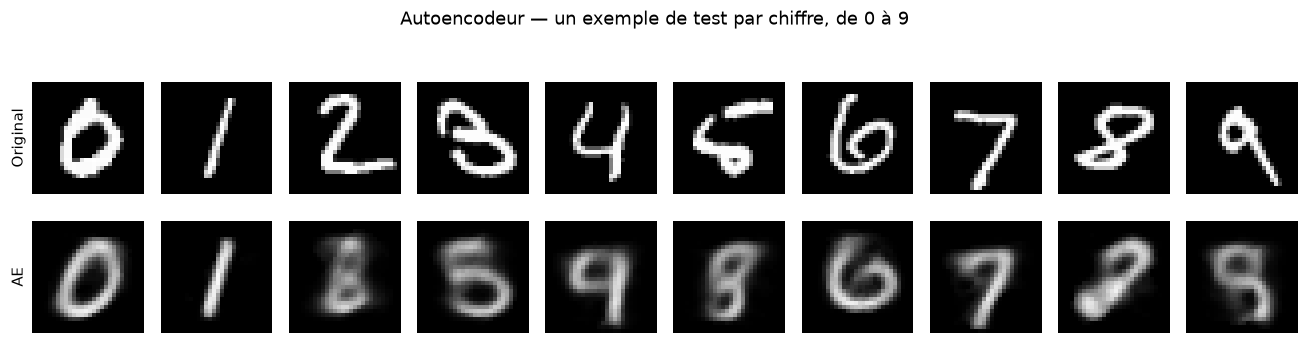

In [12]:
@torch.no_grad()
def reconstruction_grid(originals, reconstructions, row_names, title, name):
    rows = [originals.cpu()] + [batch.cpu() for batch in reconstructions]
    fig, axes = plt.subplots(len(rows), len(originals), figsize=(12, 1.7 * len(rows)), squeeze=False)
    for row_index, (batch, row_name) in enumerate(zip(rows, row_names)):
        for column, ax in enumerate(axes[row_index]):
            ax.imshow(batch[column, 0], cmap="gray", vmin=0, vmax=1)
            ax.set(xticks=[], yticks=[])
            for spine in ax.spines.values():
                spine.set_visible(False)
            if column == 0:
                ax.set_ylabel(row_name, fontsize=10)
    fig.suptitle(title)
    fig.tight_layout()
    save_figure(name)

# Un exemple par chiffre, choisi dans l'ordre du test sans sélectionner les plus réussis.
example_indices = [torch.where(mnist_test.targets == digit)[0][0].item() for digit in range(10)]
example_images = torch.stack([test_dataset[index][0] for index in example_indices]).to(device)
ae.eval()
with torch.no_grad():
    ae_examples = ae(example_images)
reconstruction_grid(example_images, [ae_examples], ["Original", "AE"],
                    "Autoencodeur — un exemple de test par chiffre, de 0 à 9", "06_reconstructions_ae")

### 3.2 Espace latent, prototypes et interpolation

**Observation de l'exécution enregistrée.** Dans les reconstructions ci-dessus, le 0 et
le 1 restent bien reconnaissables, tandis que les formes du 2, du 3, du 5 et du 8 deviennent
plus ambiguës. La faible MSE ne signifie donc pas que chaque chiffre conserve son identité.

Les images de test sont projetées dans le plan latent ; les couleurs correspondent aux
vraies classes, ajoutées **uniquement pour l'affichage**. Des regroupements éventuels ne
signifient pas que l'AE ait appris une classification supervisée.
Un prototype est le décodage du code latent moyen des images **d'apprentissage** d'une
classe. C'est une exploration guidée par les labels après apprentissage, pas un AE conditionnel.

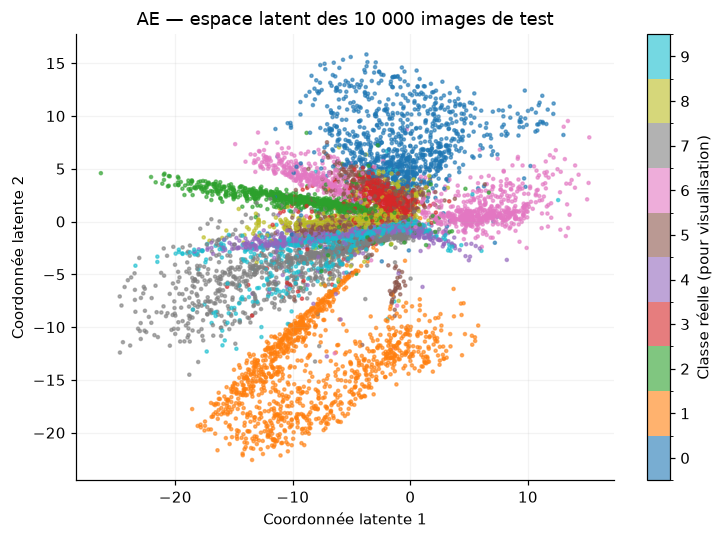

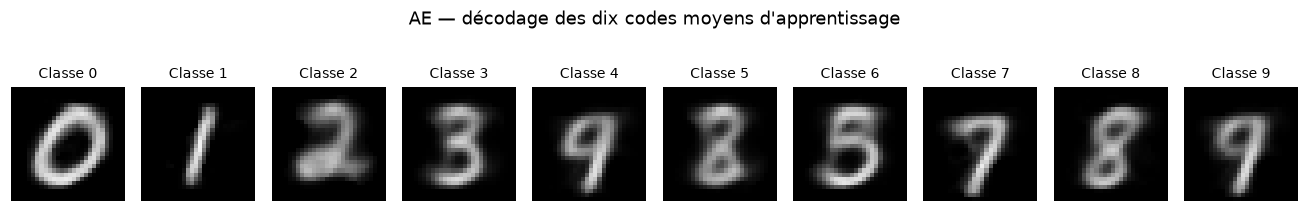

In [13]:
@torch.no_grad()
def latent_codes(model, loader, variational=False):
    model.eval()
    codes, targets = [], []
    for x, y in loader:
        encoded = model.encode(x.to(device))
        codes.append((encoded[0] if variational else encoded).cpu())
        targets.append(y)
    return torch.cat(codes), torch.cat(targets)

def plot_latent(codes, targets, title, name):
    fig, ax = plt.subplots(figsize=(7, 5))
    cmap = plt.get_cmap("tab10")
    points = ax.scatter(codes[:, 0], codes[:, 1], c=targets, cmap=cmap,
                        norm=BoundaryNorm(np.arange(-.5, 10.5, 1), cmap.N), s=4, alpha=.6, rasterized=True)
    fig.colorbar(points, ax=ax, ticks=range(10), label="Classe réelle (pour visualisation)")
    ax.set(title=title, xlabel="Coordonnée latente 1", ylabel="Coordonnée latente 2")
    ax.grid(alpha=.15)
    fig.tight_layout()
    save_figure(name)

ae_test_codes, latent_labels = latent_codes(ae, test_loader)
plot_latent(ae_test_codes.numpy(), latent_labels.numpy(), "AE — espace latent des 10 000 images de test", "07_espace_latent_ae")
ae_train_codes, train_labels = latent_codes(ae, train_eval_loader)
prototype_codes = torch.stack([ae_train_codes[train_labels == digit].mean(0) for digit in range(10)])
with torch.no_grad():
    prototypes = ae.decode(prototype_codes.to(device)).cpu()
fig, axes = plt.subplots(1, 10, figsize=(12, 2.2))
for digit, ax in enumerate(axes):
    ax.imshow(prototypes[digit, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe {digit}", fontsize=9)
    ax.axis("off")
fig.suptitle("AE — décodage des dix codes moyens d'apprentissage")
fig.tight_layout()
save_figure("08_prototypes_ae")

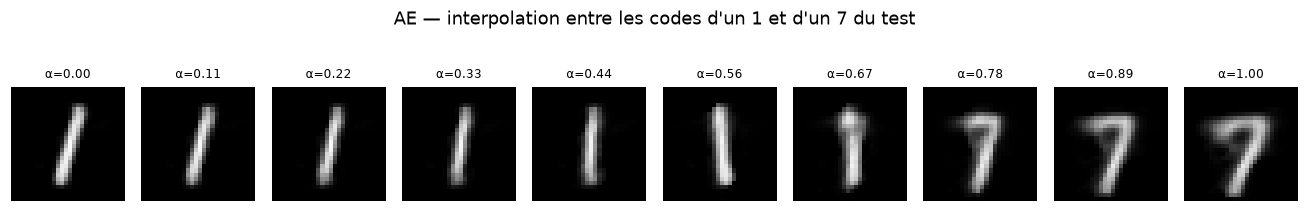

**Limite de l'AE.** Sa perte impose une bonne reconstruction des codes observés, sans imposer de loi connue à l'espace latent. Une interpolation peut traverser des régions peu apprises. Tirer un vecteur gaussien ne garantit donc pas une génération pertinente.

In [14]:
@torch.no_grad()
def interpolation(model, start_image, end_image, name, title, variational=False):
    model.eval()
    first = model.encode(start_image.unsqueeze(0))
    last = model.encode(end_image.unsqueeze(0))
    first, last = (first[0], last[0]) if variational else (first, last)
    alpha = torch.linspace(0, 1, 10, device=device).unsqueeze(1)
    images = model.decode((1 - alpha) * first + alpha * last).cpu()
    fig, axes = plt.subplots(1, 10, figsize=(12, 2.2))
    for index, ax in enumerate(axes):
        ax.imshow(images[index, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"α={alpha[index].item():.2f}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    save_figure(name)

interpolation(ae, example_images[1], example_images[7], "09_interpolation_ae",
              "AE — interpolation entre les codes d'un 1 et d'un 7 du test")
display(Markdown("**Limite de l'AE.** Sa perte impose une bonne reconstruction des codes observés, "
                 "sans imposer de loi connue à l'espace latent. Une interpolation peut traverser des régions "
                 "peu apprises. Tirer un vecteur gaussien ne garantit donc pas une génération pertinente."))

## 4. Créer, entraîner, évaluer et explorer un VAE

Le VAE associe une image à une distribution latente gaussienne diagonale :

$$q_\phi(z|x)=\mathcal N(\mu(x),\operatorname{diag}(\exp(\log\sigma^2(x)))).$$

L'encodeur `784 → 256 → 64` produit séparément `mu` et `logvar`, chacun de dimension 2.
Le décodeur suit `2 → 64 → 256 → 784`. Pour permettre la rétropropagation à travers
l'échantillonnage, on utilise la **reparamétrisation** :

$$z=\mu+\exp(\tfrac12\log\sigma^2)\odot\epsilon,\qquad\epsilon\sim\mathcal N(0,I).$$

On minimise, par image :

$$\mathcal L_{VAE}=\underbrace{\sum_{p=1}^{784}\operatorname{BCE}(\hat x_p,x_p)}_{\text{reconstruction}}
+\beta\underbrace{\frac12\sum_j(\mu_j^2+\exp(\log\sigma_j^2)-1-\log\sigma_j^2)}_{D_{KL}(q_\phi(z|x)\|\mathcal N(0,I))}.$$

Ici **β = 1**. La BCE est une vraisemblance de type Bernoulli utilisée comme objectif
de reconstruction des intensités ramenées dans `[0, 1]`. On utilise `binary_cross_entropy_with_logits`
pour la stabilité numérique et on applique la sigmoïde seulement pour obtenir les pixels.
La BCE est **sommée sur les pixels, puis moyennée sur les images**, tout comme la KL.
Cela préserve leur poids relatif ; moyenner la BCE sur les pixels en conservant la KL
inchangée modifierait fortement le problème.

In [15]:
class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 64), nn.ReLU())
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 64), nn.ReLU(), nn.Linear(64, 256),
                                     nn.ReLU(), nn.Linear(256, 784))

    def encode(self, x):
        hidden = self.encoder(x)
        return self.fc_mu(hidden), self.fc_logvar(hidden)

    def reparameterize(self, mu, logvar):
        return mu + torch.exp(.5 * logvar) * torch.randn_like(mu)

    def decode_logits(self, z):
        return self.decoder(z).reshape(-1, 1, 28, 28)

    def decode(self, z):
        return torch.sigmoid(self.decode_logits(z))

    def forward(self, x):
        mu, logvar = self.encode(x)
        logits = self.decode_logits(self.reparameterize(mu, logvar))
        return logits, mu, logvar

def vae_loss(logits, x, mu, logvar, beta=BETA):
    reconstruction = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x)
    kl = -.5 * (1 + logvar - mu.square() - logvar.exp()).sum(1).mean()
    return reconstruction + beta * kl, reconstruction, kl

def vae_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    sums = {key: 0.0 for key in ("loss", "bce", "kl", "mse")}
    count = 0
    # Le bruit de validation est fixé pour comparer les époques sans modifier le RNG d'entraînement.
    cuda_devices = [torch.cuda.current_device()] if device.type == "cuda" else []
    with torch.random.fork_rng(devices=cuda_devices, enabled=not training):
        if not training:
            torch.manual_seed(SEED + 1)
        with torch.set_grad_enabled(training):
            for x, _ in loader:
                x = x.to(device)
                logits, mu, logvar = model(x)
                loss, reconstruction, kl = vae_loss(logits, x, mu, logvar)
                if not torch.isfinite(loss):
                    raise RuntimeError("Perte VAE non finie")
                if training:
                    optimizer.zero_grad(set_to_none=True)
                    loss.backward()
                    optimizer.step()
                mse = F.mse_loss(torch.sigmoid(logits.detach()), x).item()
                for key, value in zip(sums, (loss.item(), reconstruction.item(), kl.item(), mse)):
                    sums[key] += value * len(x)
                count += len(x)
    return {key: value / count for key, value in sums.items()}

seed_everything()
vae = VAE().to(device)
history_vae, best_vae, time_vae = fit(vae, vae_epoch, EPOCHS_VAE, "vae")

vae 01/20 | apprentissage=217.13236 | validation=184.99993


vae 02/20 | apprentissage=173.70580 | validation=168.97055


vae 03/20 | apprentissage=167.00184 | validation=165.17560


vae 04/20 | apprentissage=163.90381 | validation=162.45252


vae 05/20 | apprentissage=160.96485 | validation=159.45880


vae 06/20 | apprentissage=158.58709 | validation=157.64350


... (11 outputs left out)

vae 18/20 | apprentissage=146.94547 | validation=148.06017


vae 19/20 | apprentissage=146.54494 | validation=147.76398


vae 20/20 | apprentissage=146.05787 | validation=147.22982


Meilleure époque retenue : 20 | durée : 131.3 s


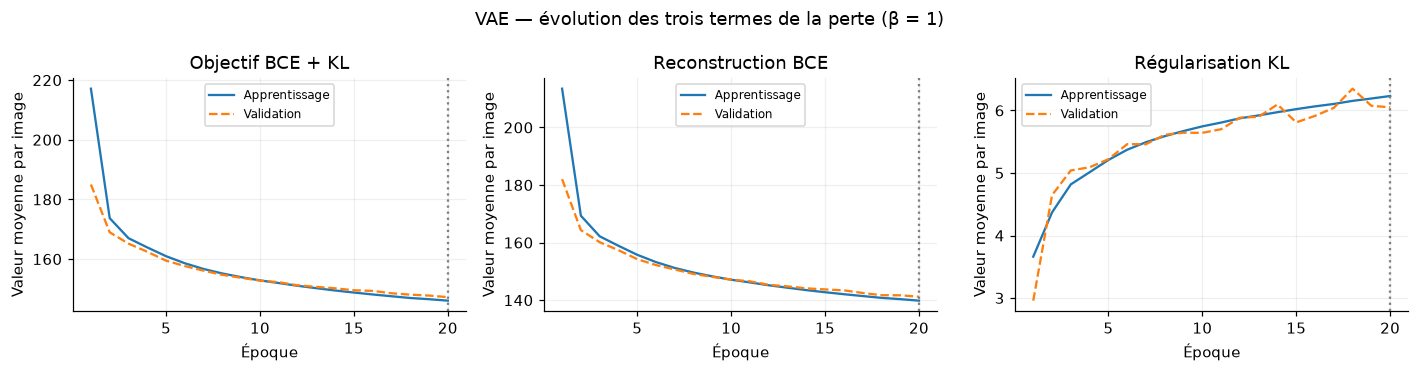

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, key, title in zip(axes, ("loss", "bce", "kl"), ("Objectif BCE + KL", "Reconstruction BCE", "Régularisation KL")):
    for prefix, label, style in (("train", "Apprentissage", "-"), ("val", "Validation", "--")):
        ax.plot([row["epoch"] for row in history_vae], [row[f"{prefix}_{key}"] for row in history_vae], style, label=label)
    ax.axvline(best_vae, color="gray", linestyle=":")
    ax.set(title=title, xlabel="Époque", ylabel="Valeur moyenne par image")
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.suptitle("VAE — évolution des trois termes de la perte (β = 1)")
fig.tight_layout()
save_figure("10_courbes_vae")

### 4.1 Évaluation sur les 10 000 images de test

L'objectif du VAE dépend d'un tirage aléatoire. Son estimation sur le test moyenne ici
**5 tirages par image**, avec une graine fixée. La KL ne dépend pas de ces tirages.
Pour comparer les reconstructions à celles de l'AE, on calcule aussi la MSE de
`decode(mu(x))`, une reconstruction déterministe. Elle est distincte de la MSE obtenue
en tirant `z ~ q(z|x)`. L'opposé de l'objectif à β = 1 estime l'ELBO pour le modèle choisi,
et ne constitue pas la log-vraisemblance exacte.

**Test VAE :** BCE = **141.30** ; KL = **6.05** ; objectif = **147.34 par image**. MSE via μ = **0.03945 par pixel** ; MSE avec échantillonnage = **0.03995**.

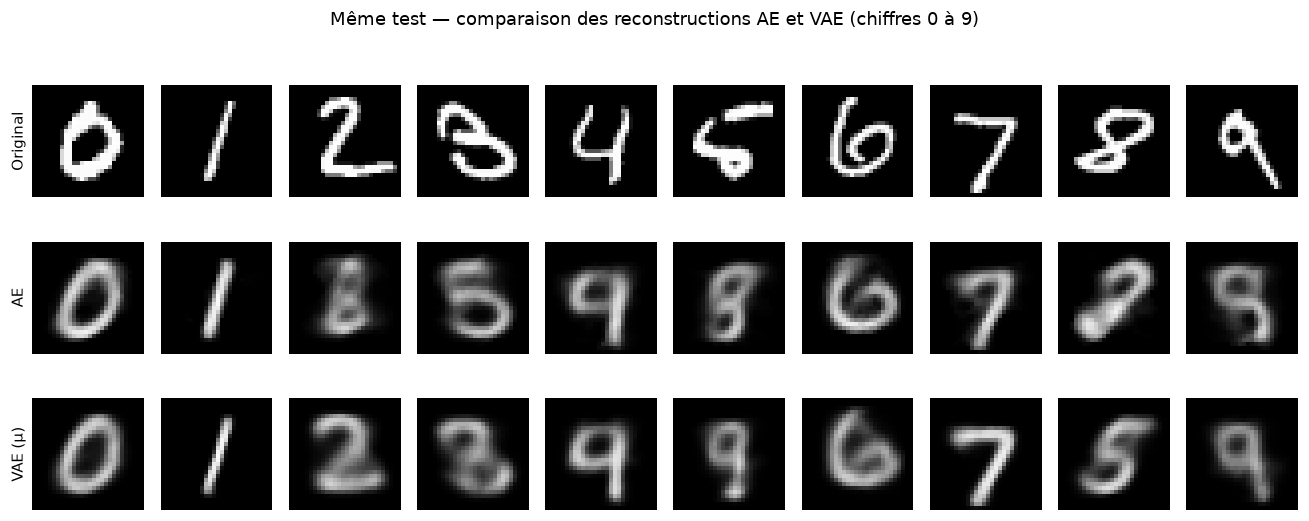

In [17]:
@torch.no_grad()
def evaluate_vae(model, loader, samples=MC_TEST):
    model.eval()
    totals = {key: 0.0 for key in ("bce", "kl", "mse_mu", "mse_sample")}
    count = 0
    cuda_devices = [torch.cuda.current_device()] if device.type == "cuda" else []
    with torch.random.fork_rng(devices=cuda_devices):
        torch.manual_seed(SEED + 2)
        for x, _ in loader:
            x = x.to(device)
            mu, logvar = model.encode(x)
            totals["kl"] += (-.5 * (1 + logvar - mu.square() - logvar.exp()).sum()).item()
            totals["mse_mu"] += F.mse_loss(model.decode(mu), x, reduction="sum").item() / 784
            for _ in range(samples):
                logits = model.decode_logits(model.reparameterize(mu, logvar))
                totals["bce"] += F.binary_cross_entropy_with_logits(logits, x, reduction="sum").item() / samples
                totals["mse_sample"] += F.mse_loss(torch.sigmoid(logits), x, reduction="sum").item() / (samples * 784)
            count += len(x)
    result = {key: value / count for key, value in totals.items()}
    result["loss"] = result["bce"] + BETA * result["kl"]
    return result

test_vae = evaluate_vae(vae, test_loader)
test_vae["best_epoch"] = best_vae
display(Markdown(f"**Test VAE :** BCE = **{test_vae['bce']:.2f}** ; KL = **{test_vae['kl']:.2f}** ; "
                 f"objectif = **{test_vae['loss']:.2f} par image**. "
                 f"MSE via μ = **{test_vae['mse_mu']:.5f} par pixel** ; "
                 f"MSE avec échantillonnage = **{test_vae['mse_sample']:.5f}**."))
with torch.no_grad():
    example_mu, _ = vae.encode(example_images)
    vae_examples = vae.decode(example_mu)
reconstruction_grid(example_images, [ae_examples, vae_examples], ["Original", "AE", "VAE (μ)"],
                    "Même test — comparaison des reconstructions AE et VAE (chiffres 0 à 9)", "11_comparaison_reconstructions")

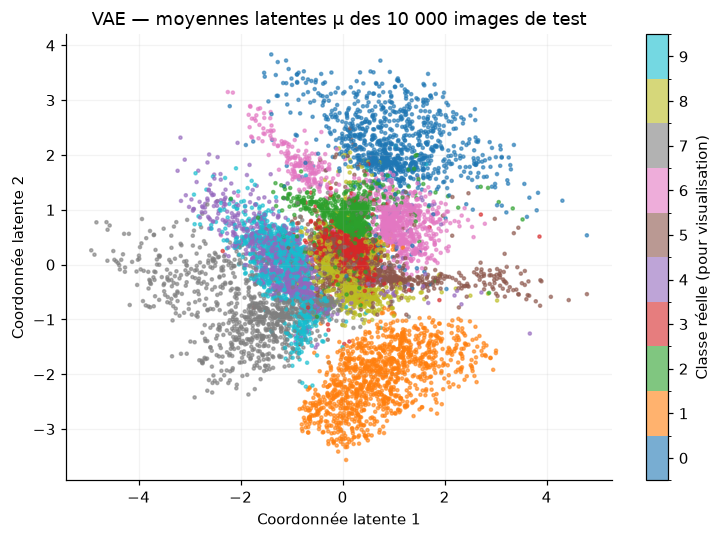

**Lecture de l'espace latent.** La KL encourage chaque distribution encodée à rester proche de N(0, I). Elle ne garantit ni des classes parfaitement séparées, ni une distribution agrégée exactement gaussienne. Le nuage représente les moyennes μ, pas les échantillons z.

In [18]:
vae_test_codes, vae_labels = latent_codes(vae, test_loader, variational=True)
plot_latent(vae_test_codes.numpy(), vae_labels.numpy(), "VAE — moyennes latentes μ des 10 000 images de test", "12_espace_latent_vae")
display(Markdown("**Lecture de l'espace latent.** La KL encourage chaque distribution encodée à rester proche "
                 "de N(0, I). Elle ne garantit ni des classes parfaitement séparées, ni une distribution agrégée "
                 "exactement gaussienne. Le nuage représente les moyennes μ, pas les échantillons z."))

### 4.2 Générer de nouveaux chiffres sans image d'entrée

On tire `z ~ N(0, I)`, puis on calcule `sigmoid(decode_logits(z))`.
Les images affichées sont les **probabilités de pixels** du décodeur, comme dans le cours,
ce qui peut produire un aspect flou. Un échantillonnage Bernoulli des pixels serait une
autre étape possible. Le VAE n'est pas conditionnel : on ne choisit pas directement la classe générée.
Les vingt premiers tirages sont tous affichés, sans sélection visuelle.

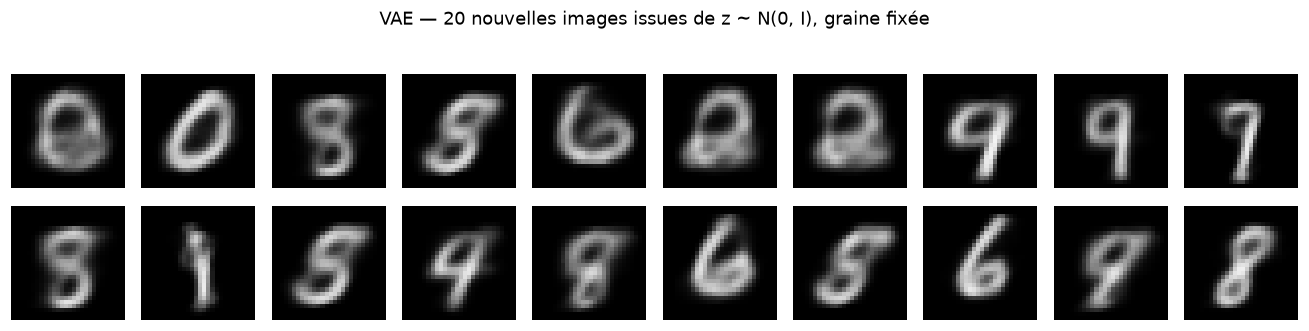

In [19]:
latent_generator = torch.Generator().manual_seed(SEED + 3)
random_codes = torch.randn(20, LATENT_DIM, generator=latent_generator).to(device)
with torch.no_grad():
    generated = vae.decode(random_codes).cpu()
assert generated.shape == (20, 1, 28, 28)
assert torch.isfinite(generated).all() and generated.min() >= 0 and generated.max() <= 1
fig, axes = plt.subplots(2, 10, figsize=(12, 3.2))
for index, ax in enumerate(axes.flat):
    ax.imshow(generated[index, 0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
fig.suptitle("VAE — 20 nouvelles images issues de z ~ N(0, I), graine fixée")
fig.tight_layout()
save_figure("13_generation_vae")

### 4.3 Explorer une grille latente et interpoler

**Observation des générations ci-dessus.** Les vingt tirages montrent plusieurs formes
reconnaissables (notamment des 0, 1, 5, 6, 7 et 9), avec des traits flous et quelques images
ambiguës. Ce petit échantillon ne permet pas d'établir la couverture des dix classes.

Une grille de 15 × 15 coordonnées entre −3 et 3 est décodée. Chaque case montre
une image différente ; une évolution progressive des formes rend la continuité observable.
Les coins de la grille sont moins probables sous la loi normale et peuvent être moins bien appris.
L'interpolation utilise `z(α) = (1 − α) μ(x₁) + α μ(x₂)`.
Dans la grille de cette exécution, les formes proches de 0 occupent le haut à droite,
celles proches de 1 le bas à droite, avec des transitions et des formes intermédiaires.

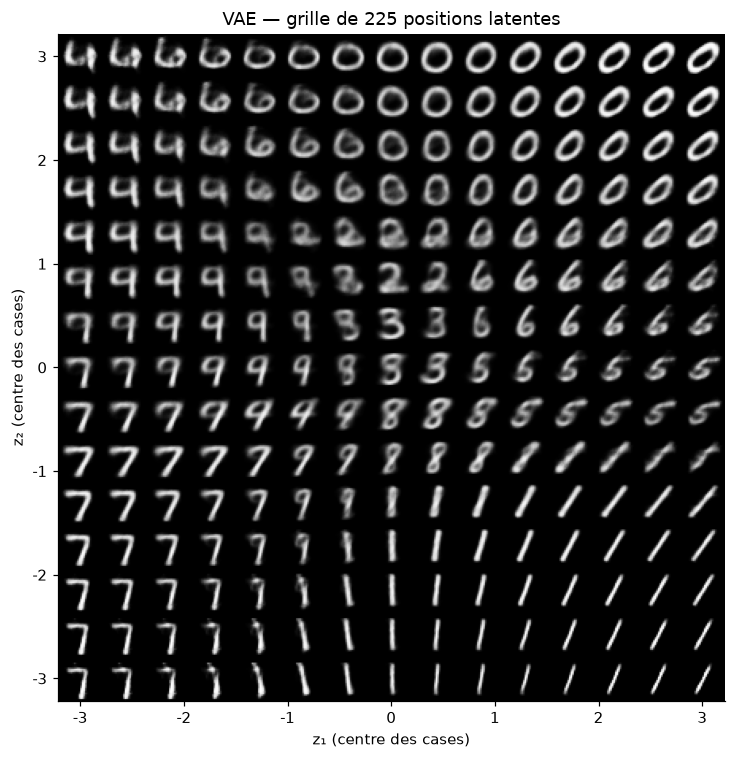

In [20]:
grid_size = 15
grid_values = torch.linspace(-3, 3, grid_size)
grid_y, grid_x = torch.meshgrid(grid_values.flip(0), grid_values, indexing="ij")
grid_codes = torch.stack((grid_x.flatten(), grid_y.flatten()), dim=1).to(device)
with torch.no_grad():
    grid_images = vae.decode(grid_codes).cpu().numpy()[:, 0]
mosaic = grid_images.reshape(grid_size, grid_size, 28, 28).transpose(0, 2, 1, 3).reshape(28 * grid_size, 28 * grid_size)
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(mosaic, cmap="gray", vmin=0, vmax=1)
positions = np.linspace(13.5, 28 * grid_size - 14.5, 7)
ax.set_xticks(positions, [f"{value:.0f}" for value in np.linspace(-3, 3, 7)])
ax.set_yticks(positions, [f"{value:.0f}" for value in np.linspace(3, -3, 7)])
ax.set(xlabel="z₁ (centre des cases)", ylabel="z₂ (centre des cases)", title="VAE — grille de 225 positions latentes")
fig.tight_layout()
save_figure("14_grille_latente_vae")

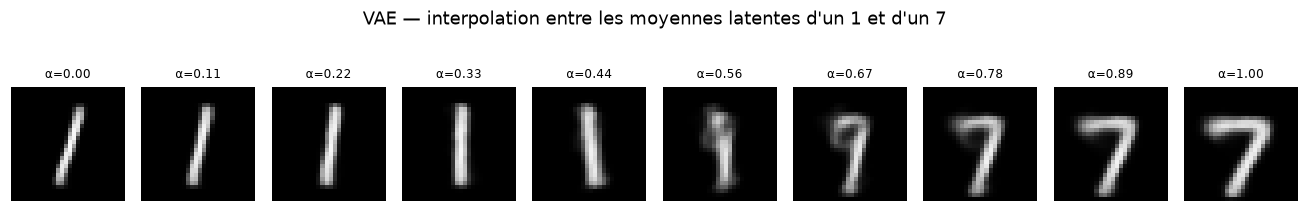

In [21]:
interpolation(vae, example_images[1], example_images[7], "15_interpolation_vae",
              "VAE — interpolation entre les moyennes latentes d'un 1 et d'un 7", variational=True)

## 5. Vérifications et bilan

Les modèles sont évalués selon leur objectif. Pour l'AE et le VAE, la MSE par pixel
permet une comparaison de reconstruction sur le même jeu de test. **Elle ne mesure pas
la qualité de la génération**. Une BCE du VAE ne doit pas être comparée numériquement à
la MSE de l'AE. Le classifieur traite encore une autre tâche.

La référence « image moyenne » est indépendante des deux architectures ; tous les pixels
comptent dans sa MSE comme dans celle des modèles. Les pixels noirs majoritaires peuvent
réduire la MSE sans préserver tous les détails des chiffres.

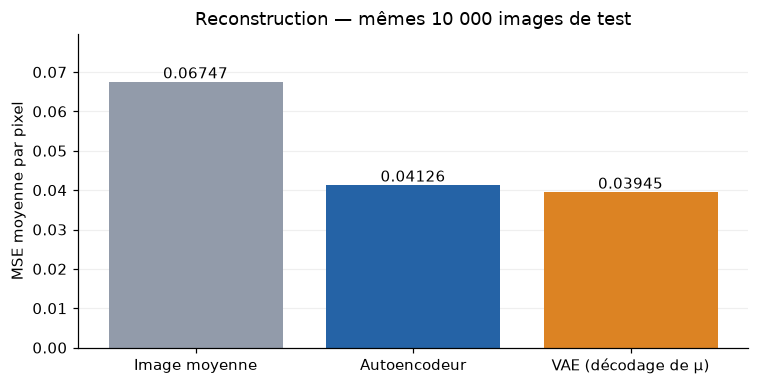

In [22]:
fig, ax = plt.subplots(figsize=(7, 3.6))
names = ["Image moyenne", "Autoencodeur", "VAE (décodage de μ)"]
values = [baseline_mse, test_ae["mse"], test_vae["mse_mu"]]
bars = ax.bar(names, values, color=["#929baa", "#2563a6", "#dc8323"])
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:.5f}", ha="center", va="bottom")
ax.set(title="Reconstruction — mêmes 10 000 images de test", ylabel="MSE moyenne par pixel", ylim=(0, max(values) * 1.18))
ax.grid(axis="y", alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
save_figure("16_comparaison_mse")

In [23]:
assert 0 <= test_classifier["accuracy"] <= 1
assert torch.isfinite(torch.tensor([test_ae["mse"], *[test_vae[key] for key in ("bce", "kl", "loss", "mse_mu")]])).all()
assert test_vae["kl"] >= -1e-6
assert abs(test_vae["loss"] - test_vae["bce"] - BETA * test_vae["kl"]) < 1e-6
with torch.no_grad():
    assert classifier(example_images).shape == (10, 10)
    assert ae(example_images).shape == example_images.shape
    mu, logvar = vae.encode(example_images)
    assert mu.shape == logvar.shape == (10, LATENT_DIM)
    assert vae.decode(mu).shape == example_images.shape

configuration = {"seed": SEED, "n_train": len(train_dataset), "n_validation": len(validation_dataset),
                 "n_test": len(test_dataset), "batch_size": BATCH_SIZE, "latent_dim": LATENT_DIM,
                 "epochs_classifier": EPOCHS_CLASSIFIER, "epochs_ae": EPOCHS_AE, "epochs_vae": EPOCHS_VAE,
                 "learning_rate": LEARNING_RATE, "beta": BETA, "mc_test": MC_TEST,
                 "device": str(device), "python": platform.python_version()}
metrics = {"configuration": configuration, "versions": versions, "classifieur": test_classifier,
           "autoencodeur": test_ae, "vae": test_vae,
           "temps_secondes": {"classifieur": time_classifier, "autoencodeur": time_ae, "vae": time_vae},
           "validation": {"split_disjoint": True, "accuracy_torcheval": accuracy_torcheval,
                          "confusion_total": confusion.sum().item()}}
(OUTPUT_DIR / "metriques.json").write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")
(OUTPUT_DIR / "matrice_confusion.json").write_text(json.dumps(confusion.tolist()), encoding="utf-8")
print("Vérifications réussies : partitions, formes, plages de pixels, pertes finies, accuracy Torcheval et matrice de confusion.")
print("Mesures :", OUTPUT_DIR / "metriques.json")
print("Courbes :", OUTPUT_DIR / "historique_*.csv")
print("Figures :", FIGURE_DIR)
print("Paramètres des meilleurs modèles :", MODEL_DIR)

Vérifications réussies : partitions, formes, plages de pixels, pertes finies, accuracy Torcheval et matrice de confusion.
Mesures : C:\Users\HUAWEI\Documents\ChatGPT\tp2\resultats\metriques.json
Courbes : C:\Users\HUAWEI\Documents\ChatGPT\tp2\resultats\historique_*.csv
Figures : C:\Users\HUAWEI\Documents\ChatGPT\tp2\resultats\figures
Paramètres des meilleurs modèles : C:\Users\HUAWEI\Documents\ChatGPT\tp2\resultats\modeles


In [24]:
ae_gain = 1 - test_ae["mse"] / baseline_mse
vae_gain = 1 - test_vae["mse_mu"] / baseline_mse
display(Markdown(
    "### Conclusion des mesures\n\n"
    f"Le **classifieur** atteint **{accuracy:.2%}** de précision sur les 10 000 images de test. "
    f"Son meilleur modèle selon la perte de validation provient de l'époque **{best_classifier}**.\n\n"
    f"L'**autoencodeur**, retenu à l'époque **{best_ae}**, obtient une MSE de **{test_ae['mse']:.5f}** par pixel, "
    f"contre **{baseline_mse:.5f}** pour l'image moyenne, soit une réduction de **{ae_gain:.1%}**. "
    "Il reconstruit à travers un code de dimension 2, sans apprendre une loi d'échantillonnage imposée.\n\n"
    f"Le **VAE**, retenu à l'époque **{best_vae}**, obtient une MSE déterministe de **{test_vae['mse_mu']:.5f}** "
    f"(réduction de **{vae_gain:.1%}** face à la référence), avec BCE = **{test_vae['bce']:.2f}** et "
    f"KL = **{test_vae['kl']:.2f}** par image. La régularisation rend possible la génération à partir de **N(0, I)**. "
    "Les figures de génération et de grille latente permettent d'examiner les formes obtenues ; "
    "ces métriques de reconstruction ne suffisent pas à certifier leur réalisme ou leur diversité."
))

### Conclusion des mesures

Le **classifieur** atteint **96.15%** de précision sur les 10 000 images de test. Son meilleur modèle selon la perte de validation provient de l'époque **5**.

L'**autoencodeur**, retenu à l'époque **15**, obtient une MSE de **0.04126** par pixel, contre **0.06747** pour l'image moyenne, soit une réduction de **38.8%**. Il reconstruit à travers un code de dimension 2, sans apprendre une loi d'échantillonnage imposée.

Le **VAE**, retenu à l'époque **20**, obtient une MSE déterministe de **0.03945** (réduction de **41.5%** face à la référence), avec BCE = **141.30** et KL = **6.05** par image. La régularisation rend possible la génération à partir de **N(0, I)**. Les figures de génération et de grille latente permettent d'examiner les formes obtenues ; ces métriques de reconstruction ne suffisent pas à certifier leur réalisme ou leur diversité.

### Réponses aux questions de compréhension

| Question | Réponse |
|---|---|
| Quel modèle utilise les labels à l'entraînement ? | Le classifieur. L'AE et le VAE utilisent uniquement les images. |
| Pourquoi `Flatten` ? | Une couche linéaire attend un vecteur ; l'image est transformée en 784 caractéristiques. |
| Pourquoi ne pas mettre un softmax avant `CrossEntropyLoss` ? | La fonction de perte traite déjà les logits avec un log-softmax. |
| Pourquoi utiliser Sigmoid dans les décodeurs ? | Pour obtenir des intensités dans la même plage `[0, 1]` que les images. |
| Pourquoi choisir un latent 2D ? | Pour le tracer et parcourir une grille ; ce choix limite la capacité de reconstruction. |
| Pourquoi un AE n'est-il pas directement un générateur gaussien ? | Sa perte ne contraint pas la distribution des codes à suivre N(0, I). |
| À quoi sert `logvar` ? | À paramétrer la variance positive par une sortie réelle ; l'écart-type vaut `exp(logvar / 2)`. |
| À quoi sert la reparamétrisation ? | À isoler le bruit et permettre le passage des gradients vers μ et logvar. |
| Que contrôle β ? | Le compromis entre reconstruction et rapprochement du posterior latent vers le prior. |
| Que signifie une KL proche de zéro ? | Le posterior est proche du prior ; il faut vérifier un éventuel effondrement du posterior et non conclure à une génération parfaite. |
| Pourquoi une validation distincte du test ? | Pour choisir l'époque sans optimiser les décisions à partir des résultats du test. |
| Pourquoi les images peuvent-elles paraître floues ? | Le latent 2D comprime fortement les données et le décodeur affiche des probabilités de pixels, qui peuvent lisser les détails. |

### Pistes d'approfondissement

Des expériences supplémentaires pourraient comparer des dimensions latentes 2, 8 et 16,
plusieurs graines, ou différentes valeurs de β. Elles ne sont **pas exécutées dans ce rendu**.
Les architectures AE et VAE n'ont pas le même nombre de paramètres ni la même perte :
les résultats de reconstruction ne permettent donc pas d'isoler l'effet causal de la seule KL.
Sur un autre matériel, les opérations déterministes réduisent la variabilité sans garantir
des résultats strictement identiques entre toutes les versions de bibliothèques.

### Sources

- Supports fournis : `Modeles_generatifs_pytorch (1).ipynb` et `Modeles_generatifs_pytorch_avec_explications (2).ipynb`, Pr. Mohamed YOUSSFI.
- [Documentation officielle MNIST / Torchvision](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html).
- [Documentation officielle UV avec PyTorch](https://docs.astral.sh/uv/guides/integration/pytorch/).
- [Kingma et Welling, Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114).